<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Some stuff we have to do before any of the actual programming

In [29]:
# Import packages
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import r_regression
from sklearn.linear_model import LogisticRegression

data = pd.read_csv("ED_Cleaned.csv")

Identify two attributes in the consumable usage dataset and develop a **Linear Regression** model using the identifies attributes and **sklearn.linear_model.LinearRegression**. Measure the performace of the mofel and make sure that the model performance is high. Draw a plot using **matplotlib** to show the observed and the rpedicted values.

SSE: 102073.04962100854
Residual Standard Deviation: 11.635093354818554


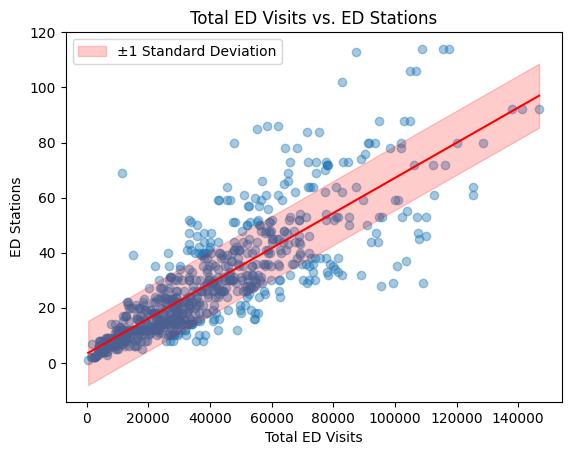

Hospitals outside ±1 std: 174
Percentage outside: 23.015873015873016


'\nThis tells us that the distribution is tighter than a normal distribution since, if it were a normal\ndistribution, there would be around 32% of the hospitals outside the ±1 standard deviation.\n'

In [13]:

# From Project Proposal, we will be Predicting ED Stations from Total ED Visits

X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["EDStations"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("Total ED Visits")
plt.ylabel("ED Stations")
plt.title("Total ED Visits vs. ED Stations")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

"""
This tells us that the distribution is tighter than a normal distribution since, if it were a normal
distribution, there would be around 32% of the hospitals outside the ±1 standard deviation.
"""

SSE: 255853337.60533172
Residual Standard Deviation: 582.518698377422


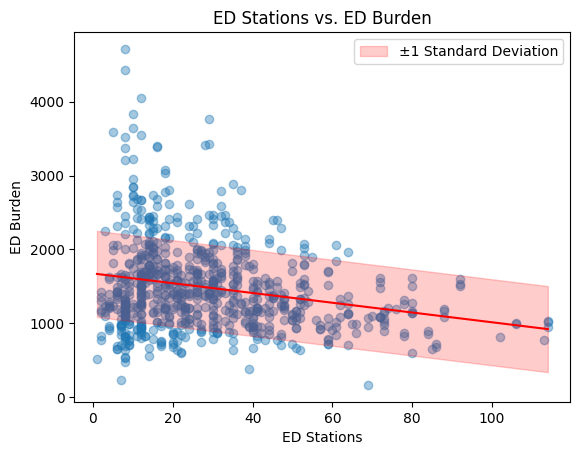

Hospitals outside ±1 std: 201
Percentage outside: 26.58730158730159


'\nThis tells us that the distribution is tighter than a normal distribution since, if it were a normal\ndistribution, there would be around 32% of the hospitals outside the ±1 standard deviation.\n\nFrom visual inspection, this seems more like an e^-x distribution. Perhaps if we did a piecewise\nregression line at 23 it could be better. We could then compare the SSE at the cutoff being 23 and\nuse numerical methods to find the best cutoff.\n'

In [23]:

# From Project Proposal, we will be Predicting ED Burden from ED Stations

y = data[["ED_Burden"]].values.reshape(-1, 1)
X = data[["EDStations"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("ED Stations")
plt.ylabel("ED Burden")
plt.title("ED Stations vs. ED Burden")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

"""
This tells us that the distribution is tighter than a normal distribution since, if it were a normal
distribution, there would be around 32% of the hospitals outside the ±1 standard deviation.

From visual inspection, this seems more like an e^-x distribution. Perhaps if we did a piecewise
regression line at 23 it could be better. We could then compare the SSE at the cutoff being 23 and
use numerical methods to find the best cutoff.
"""

SSE: 255112676.2791006
Residual Standard Deviation: 581.6749302729928


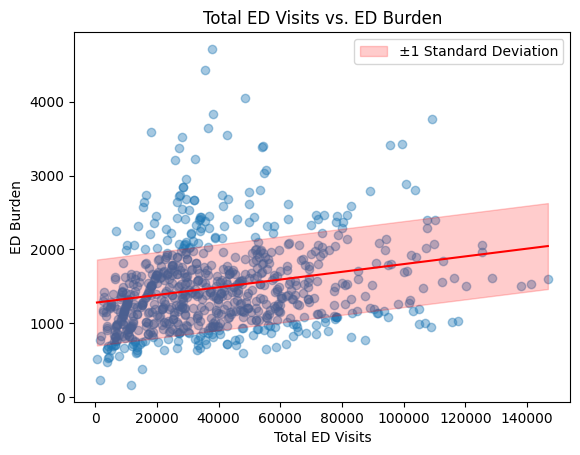

Hospitals outside ±1 std: 194
Percentage outside: 25.66137566137566


'\nThis tells us that the distribution is tighter than a normal distribution since, if it were a normal\ndistribution, there would be around 32% of the hospitals outside the ±1 standard deviation.\n\nFrom visual inspection, this seems more like a cubic distribution.\n'

In [22]:

# From Project Proposal, we will be Predicting ED Burden from Total ED Visits

y = data[["ED_Burden"]].values.reshape(-1, 1)
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

# Compute the sum of squared errors
SSEreg = np.sum((y - y_pred) ** 2)
print("SSE:", SSEreg)

# Calculate residual standard deviation
n = len(y)
std_error = np.sqrt(SSEreg / (n - 2))
print("Residual Standard Deviation:", std_error)

# Sort X values so the regression line plots correctly
order = np.argsort(X.flatten())
X_sorted = X.flatten()[order]
y_pred_sorted = y_pred.flatten()[order]

# Plot the data and regression line
plt.scatter(X, y, alpha=0.4)
plt.plot(X_sorted, y_pred_sorted, color='red')

# Add ±1 standard deviation band
plt.fill_between(
    X_sorted,
    y_pred_sorted - std_error,
    y_pred_sorted + std_error,
    color='red',
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.xlabel("Total ED Visits")
plt.ylabel("ED Burden")
plt.title("Total ED Visits vs. ED Burden")
plt.legend()
plt.show()

residuals = (y - y_pred).flatten()

outside = np.sum(np.abs(residuals) > std_error)

print("Hospitals outside ±1 std:", outside)
print("Percentage outside:", 100 * outside / len(y))

"""
This tells us that the distribution is tighter than a normal distribution since, if it were a normal
distribution, there would be around 32% of the hospitals outside the ±1 standard deviation.

From visual inspection, this seems more like a cubic distribution.
"""

Identify **more than two attributes** in the consumable usage dataset and develop a **multiple linear regression** model using the identified attributes and **sklearn.linear_model.LinearRegression**. Measure the performance of the model and male sure that the model performance is high. Draw a plot using **mplot3d** to show the observed and the predicted values.

Develop a **logistic regression** model among some identifed attributes in the consumable usage dataset and **sklearn.linear_model.LogisticRegression**. Measure the performance of the model and make sure that the model perfomance is high. Draw a plot using **matplotmib** to show the observed and the predicted values.

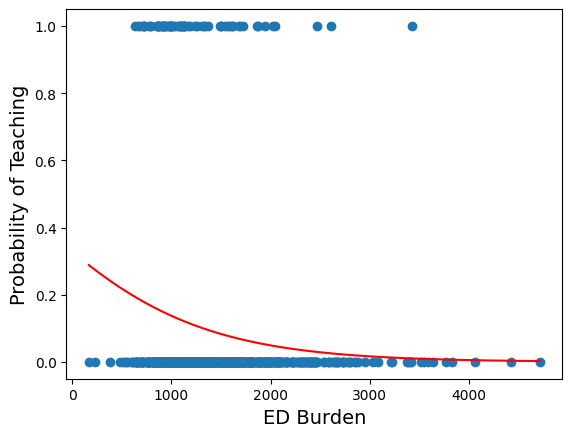

In [30]:
#From Project Proposal, we are doing Teaching Designation from ED Burden

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

"""
Not a Good Method
"""

'\n\n'

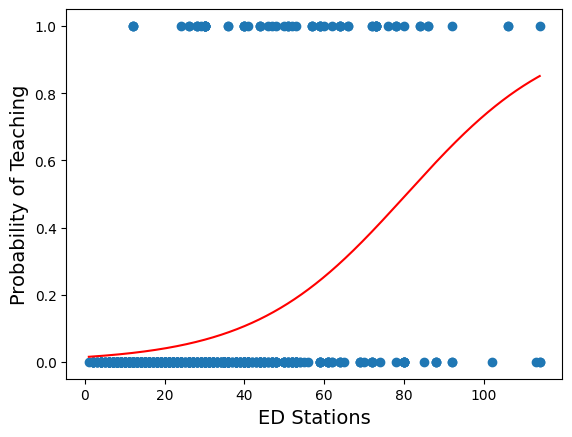

In [31]:
#From Project Proposal, we are doing Teaching Designation from ED Stations

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["EDStations"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Stations", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

"""
Not Terribly Good
"""

'\nHorrible\n'

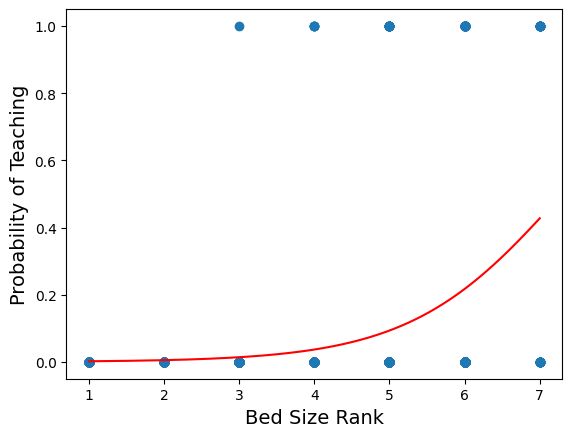

In [33]:
#From Project Proposal, we are doing Teaching Designation from Bed Size Rank

# Doing some Hot Encoding
data.loc[data["TEACHINGDesignation"] == "Non-Teaching", "TEACHINGDesignation"] = 0
data.loc[data["TEACHINGDesignation"] == "Teaching", "TEACHINGDesignation"] = 1

# Store relevant columns as variables
X = data[["Bed_Size_Rank"]].values.reshape(-1, 1)
y = data[["TEACHINGDesignation"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("Bed Size Rank", fontsize=14)
plt.ylabel("Probability of Teaching", fontsize=14);

"""
Horrible
"""

'\nHorrible\n'

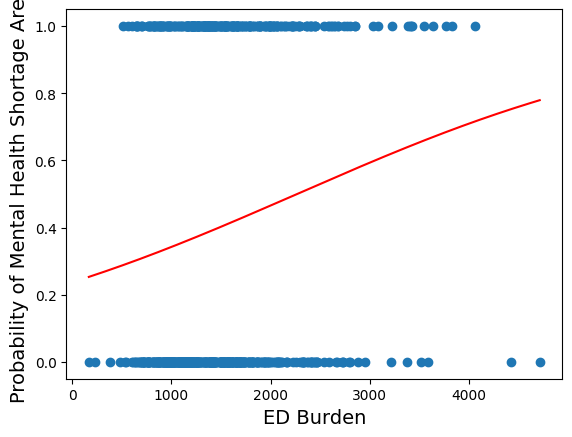

In [34]:
#From Project Proposal, we are doing Mental Health Shortage from ED Burden

# Doing some Hot Encoding
data.loc[data["MentalHealthShortageArea"] == "No", "MentalHealthShortageArea"] = 0
data.loc[data["MentalHealthShortageArea"] == "Yes", "MentalHealthShortageArea"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["MentalHealthShortageArea"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Mental Health Shortage Area", fontsize=14);

"""
Not Good
"""

'\nNot Good\n'

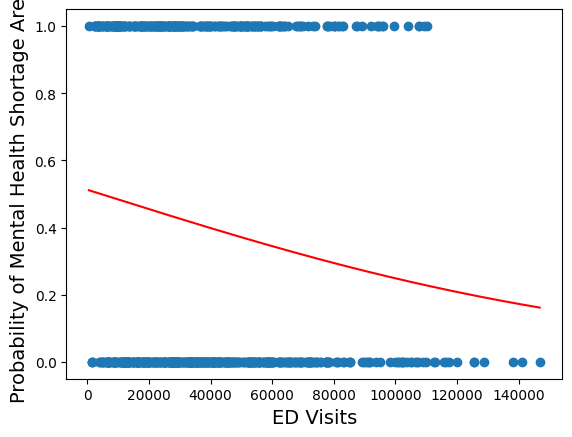

In [35]:
#From Project Proposal, we are doing Mental Health Shortage from Total ED Visits

# Doing some Hot Encoding
data.loc[data["MentalHealthShortageArea"] == "No", "MentalHealthShortageArea"] = 0
data.loc[data["MentalHealthShortageArea"] == "Yes", "MentalHealthShortageArea"] = 1

# Store relevant columns as variables
X = data[["Tot_ED_NmbVsts"]].values.reshape(-1, 1)
y = data[["MentalHealthShortageArea"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Visits", fontsize=14)
plt.ylabel("Probability of Mental Health Shortage Area", fontsize=14);

"""
Not Good
"""

'\nNot Good. Clustering may be better for a lot of these\n'

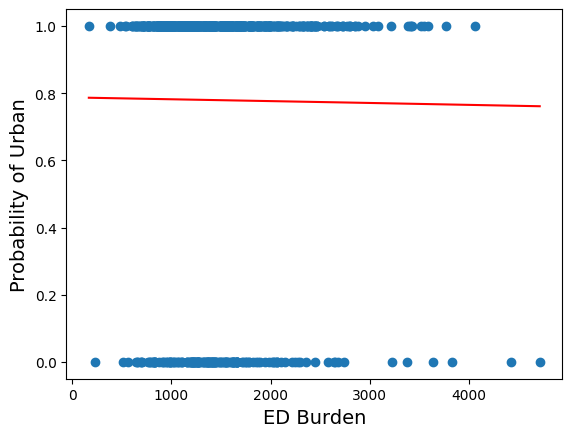

In [40]:
#From Project Proposal, we are doing Urban from ED Burden

# Doing some Hot Encoding
data.loc[data["UrbanRuralDesi"] == "Rural", "UrbanRuralDesi"] = 0
data.loc[data["UrbanRuralDesi"] == "Frontier", "UrbanRuralDesi"] = 0
data.loc[data["UrbanRuralDesi"] == "Urban", "UrbanRuralDesi"] = 1

# Store relevant columns as variables
X = data[["ED_Burden"]].values.reshape(-1, 1)
y = data[["UrbanRuralDesi"]].values.reshape(-1, 1).astype(int)

# Logistic regression predicting diagnosis from tumor radius
logisticModel = LogisticRegression()
logisticModel.fit(X, np.ravel(y.astype(int)))

# Graph logistic regression probabilities
plt.scatter(X, y)
xDelta = np.linspace(X.min(), X.max(), 10000)
yPredicted = logisticModel.predict(X).reshape(-1, 1).astype(int)
yDeltaProb = logisticModel.predict_proba(xDelta.reshape(-1, 1))[:, 1]
plt.plot(xDelta, yDeltaProb, color="red")
plt.xlabel("ED Burden", fontsize=14)
plt.ylabel("Probability of Urban", fontsize=14);

"""
Not Good. Clustering may be better for a lot of these
"""